# Choosing the markout horizon

After one of our quotes is filled, the price often keeps moving against us. That's adverse selection, and the Glosten–Milgrom premium $\hat a$ is our estimate of how big that move will be. Before we can predict it, we have to pin down exactly what we're measuring, and that comes down to one number: how long after the fill we wait before measuring the move. That wait is the **markout horizon** $h$.

The markout of a fill, in log-odds, is

$$
a = \begin{cases}
x_0 - x(t_\text{fill} + h) & \text{if our back was filled} \\
x(t_\text{fill} + h) - x_0 & \text{if our lay was filled}
\end{cases}
$$

where $x(t)$ is the runner's mid at time $t$, and $x_0$ is the mid when we **posted** the quote. A positive markout means the price went against us: after we backed, the runner drifted, or after we laid, it shortened.

We measure from the mid at posting, not at the fill, on purpose. A back usually gets filled because the price has already fallen towards it, and that fall is part of what we lose.

**Too short or too long.** If $h$ is too short, we miss part of the move, because informed money takes a while to work its way into the price. If $h$ is too long, the markout picks up a lot of price movement that has nothing to do with our fill, so it gets noisier without telling us anything new. So we plot the average markout against $h$ (the **markout curve**) and look for the point where it stops rising.

**The rule**, set before looking at any results: we take the shortest horizon from which the average markout stays at or above **90% of its 120-second level**, even at the low end of its 95% confidence interval. 120 s is the longest horizon we measure. 90% captures most of the move; chasing the last 10% would make the target a lot noisier.

**The plan**

1. Simulate pretend quotes in every January race, at every ladder price within 0.20 of the mid, filled exactly the way the backtest engine would fill them.
2. Measure each fill's markout at h = 0, 0.5, 1, 2, 3, 4 and 5 seconds, and then every 5 seconds up to 120.
3. Plot the markout curve and how noisy each horizon is, overall and by time to the off.
4. Apply the rule, and check that the answer holds for backs and lays, each distance, and each time bin.
5. Save the data the model needs: one row per filled quote, with its markout at the chosen horizon as the target.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from joblib import Parallel, delayed

# Project root = the folder that holds data/ (works whether this runs from adverse-selection/ or the root)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "processed").exists())
sys.path.insert(0, str(ROOT))
from strategies.asmodel import LADDER   # Betfair's price ladder: 1.01, 1.02, ..., 1000

FILES = sorted((ROOT / "data/processed/market_stream/Jan").glob("*/*/*.parquet"))   # one file per race
SAVE_TO = ROOT / "adverse-selection" / "data" / "pretend_fills_jan.parquet"

START, STOP = 350, 30                    # quote from 350 s before the off until T = 30 s before it
LATENCY = pd.Timedelta(seconds=0.2)      # time for an order or a cancel to reach the market
MIN_ODDS, MAX_ODDS = 1.2, 6.0            # only quote runners whose mid odds are in this range
SIDES = ["back", "lay"]
MAX_DISTANCE = 0.20                      # quote at every ladder price this close to the mid (log-odds)
DISTANCE_BANDS = [0, 0.025, 0.05, 0.10, 0.20]   # distance bands for the summaries (log-odds)
BAND_LABELS = ["0-0.025", "0.025-0.05", "0.05-0.10", "0.10-0.20"]
QUOTE_SIZE = 10                          # contracts per quote, as in the strategy (a contract pays $1 if the runner wins)
HORIZONS = [0, 0.5, 1, 2, 3, 4, 5, *range(10, 121, 5)]   # markout horizons to try, in seconds
RUNNER_EVENT = 1.0                       # markouts bigger than this are scratchings or incidents, not traders
TARGET_SHARE = 0.9                       # the rule: reach 90% of the 120 s level
N_BOOT = 1000                            # bootstrap repeats
rng = np.random.default_rng(42)          # fixed seed so the confidence intervals are reproducible

LADDER = np.array(LADDER)
LEVELS = [1, 2, 3]                       # the data keeps the best three prices on each side
LADDER_COLUMNS = [f"{side}_{what}_{i}" for side in ("back", "lay") for what in ("price", "size") for i in LEVELS]

# Chart style: thin lines, light grid. Blue = back quotes, orange = lay quotes
COLOURS = {"back": "#2a78d6", "lay": "#eb6834"}
GREY = "#b5b4ae"
plt.rcParams.update({
    "figure.figsize": (8, 4), "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8, "axes.edgecolor": GREY,
})

print(f"{len(FILES):,} January WIN markets")

4,072 January WIN markets


## Step 1: Pretend quotes

We don't run the strategy here. Instead we place pretend quotes that behave the way its quotes would, and see which ones get filled. That keeps the answer independent of things we haven't tuned yet, like γ.

**When a quote is posted.** At 350 s before the off, and again every time the runner's best back or best lay price changes, as long as its mid odds are between 1.2 and 6.0. We stop at $T$ = 30 s before the off, when the strategy pulls all its quotes. A new quote is also posted when the market reopens after a suspension.

**Where.** At every ladder price within 0.20 of the mid in log-odds. Betfair only accepts bets at prices on its price ladder (2.34 and 2.36 are allowed, 2.35 isn't), so this covers every different quote the strategy could place in that range. Backs go at every price with longer odds than the mid, out to 0.20 below it in log-odds, and lays at every price with shorter odds, out to 0.20 above it. We record each quote's distance from the mid in log-odds.

Each one is a separate pretend quote for 10 contracts, the strategy's quote size. A contract pays $1 if the runner wins, so the stake is 10 ÷ odds dollars.

**How long it stays.** An order takes 0.2 s to reach the market. When the best prices change, the strategy would cancel the quote, and the cancel takes 0.2 s as well. Until it lands, the quote can still be hit at its old price. That's being *picked off*, and it's a big part of adverse selection. A suspension wipes out every quote.

**How it gets filled.** These are the same three rules as the backtest engine (`backtest/execution.py`):

| Fill | What happens |
|---|---|
| Crossed | The other side of the book moves onto our price, so we're matched with the money offered there. |
| Traded through | Someone trades at a price that's worse for them than ours. They'd have taken our better price first. |
| Queue used up | We wait at the back of the queue at our price. Trades at our price use up the money ahead of us, and once it's gone, the rest comes to us. |

Betfair counts traded volume twice (once for each side of a matched bet), so traded amounts are halved, as in the engine.

A quote can be filled **in pieces**. At each update it's matched with as much as these rules allow, until all 10 contracts are filled. Each piece is a separate fill, with its own time and markout.

**One simplification.** The real strategy only moves a quote when its rounded ladder price changes, so it sometimes keeps its place in the queue through a small move in the mid. Our pretend quotes are re-posted at every change, so they lose their place in the queue a little more often.

In [2]:
def load_book(path):
    # One race's book updates from 400 s before the off up to the off: one row per runner per update,
    # sorted by runner and then time, with time to the off and the mid added
    book = pd.read_parquet(path, columns=["publish_time", "market_time", "status", "selection_id",
                                          *LADDER_COLUMNS, "traded_prices", "traded_sizes"])
    book = book.astype({column: float for column in LADDER_COLUMNS})   # an abandoned race stores empty prices
    off = book["market_time"].iloc[-1]                                  # scheduled off (its final value)
    book["ttj"] = (off - book["publish_time"]).dt.total_seconds()       # seconds before the off
    book = book[book["ttj"].between(0, 400)].copy()
    book["publish_time"] = book["publish_time"].dt.as_unit("ns")        # merge_asof needs one time unit
    S = 0.5 * (1 / book["back_price_1"] + 1 / book["lay_price_1"])      # mid, as a probability
    book["odds"] = 1 / S
    book["x"] = np.log(S / (1 - S))                                     # mid, in log-odds
    return book.sort_values(["selection_id", "publish_time"], kind="stable").reset_index(drop=True)


def round_up(odds):
    # Smallest ladder price at or above the odds (a back's price moves away from the mid)
    return LADDER[np.searchsorted(LADDER, odds - 1e-9)]


def round_down(odds):
    # Largest ladder price at or below the odds (a lay's price moves away from the mid)
    return LADDER[np.searchsorted(LADDER, odds + 1e-9, side="right") - 1]


def runs(first, count):
    # first, first + 1, ..., first + count - 1 for each pair, all joined together
    return np.repeat(first, count) + np.arange(count.sum()) - np.repeat(np.cumsum(count) - count, count)


def distance_band(distance):
    # Which distance band (from DISTANCE_BANDS) each quote falls in
    return pd.cut(distance, DISTANCE_BANDS, labels=BAND_LABELS)


def find_update(book, runners, times, direction):
    # The row of each runner's update at or after ("forward") or at or before ("backward") each time
    wanted = pd.DataFrame({"selection_id": runners, "time": times}).reset_index(drop=True)
    wanted["order"] = np.arange(len(wanted))
    updates = book[["selection_id", "publish_time"]].reset_index(names="row")
    found = pd.merge_asof(wanted.sort_values("time"), updates.sort_values("publish_time", kind="stable"),
                          left_on="time", right_on="publish_time", by="selection_id", direction=direction)
    return found.sort_values("order")["row"].to_numpy()

First, the moments when the strategy would act. At each one it cancels the runner's current quote (if there is one) and, if the runner is quotable, posts a new one. A quote is live from when it arrives until the next moment's cancel arrives.

In [3]:
def post_quotes(book):
    # Every pretend quote: who, which side, how far from the mid, its price, and the rows of the book
    # where it arrives in the market and where its cancel arrives
    runner = book["selection_id"]
    previous = book.groupby("selection_id")[["back_price_1", "lay_price_1", "status"]].shift()
    in_window, past_T = book["ttj"] <= START, book["ttj"] <= STOP

    # A missing price counts as 0 here, so two missing prices in a row don't count as a change
    best_changed = ((book["back_price_1"].fillna(0) != previous["back_price_1"].fillna(0))
                    | (book["lay_price_1"].fillna(0) != previous["lay_price_1"].fillna(0)))
    reopened = (book["status"] == "OPEN") & (previous["status"] != "OPEN")
    first_in_window = in_window & ~in_window.groupby(runner).shift(fill_value=False)
    first_past_T = past_T & ~past_T.groupby(runner).shift(fill_value=False)

    acts = (in_window & ~past_T & (best_changed | reopened | first_in_window)) | first_past_T
    moments = book.loc[acts, ["selection_id", "publish_time", "ttj", "status", "odds", "x"]].copy()
    moments["arrival_row"] = find_update(book, moments["selection_id"], moments["publish_time"] + LATENCY, "forward")
    moments["end_row"] = moments.groupby("selection_id")["arrival_row"].shift(-1)     # the next moment's cancel
    last_row = pd.Series(book.index, index=book.index).groupby(runner).max()
    moments["end_row"] = moments["end_row"].fillna(moments["selection_id"].map(last_row))

    posts = (moments["status"] == "OPEN") & (moments["ttj"] > STOP) \
        & moments["odds"].between(MIN_ODDS, MAX_ODDS) & moments["arrival_row"].notna()
    posted = moments[posts]

    quotes = []
    for side in SIDES:
        if side == "back":    # longer odds than the mid, out to MAX_DISTANCE below it in log-odds
            first = np.searchsorted(LADDER, posted["odds"].to_numpy() + 1e-9)
            last = np.searchsorted(LADDER, 1 + np.exp(-(posted["x"].to_numpy() - MAX_DISTANCE)) + 1e-9) - 1
        else:                 # shorter odds than the mid, out to MAX_DISTANCE above it
            first = np.searchsorted(LADDER, 1 + np.exp(-(posted["x"].to_numpy() + MAX_DISTANCE)) - 1e-9)
            last = np.searchsorted(LADDER, posted["odds"].to_numpy() - 1e-9) - 1
        count = np.clip(last - first + 1, 0, None)          # ladder prices in range for each posting
        quote = posted.iloc[np.repeat(np.arange(len(posted)), count)].reset_index(drop=True)
        quote = quote.rename(columns={"publish_time": "post_time", "ttj": "post_ttj", "x": "x0"})
        quote["side"] = side
        quote["price"] = LADDER[runs(first, count)]
        quote["distance"] = (quote["x0"] - (-np.log(quote["price"] - 1))).abs()   # from the mid, in log-odds
        quotes.append(quote)
    quotes = pd.concat(quotes, ignore_index=True).astype({"arrival_row": int, "end_row": int})
    return quotes[["selection_id", "side", "price", "distance", "post_time", "post_ttj", "x0", "arrival_row", "end_row"]]

Then, for each quote, every piece that gets matched. The queue is the only fiddly part. When our quote arrives, the money already waiting at our price is ahead of us. At each update $r$, trades at our price use some of it up. If the visible amount at our price drops below what we think is ahead of us, people ahead must have cancelled, so we move up:

$$q_r = \min\left(q_{r-1} - \text{traded}_r,\; \text{visible}_r\right)$$

and we're filled at update $r$ if $\text{traded}_r > q_{r-1}$.

Because of the min, a running total won't do. But if $C_r$ is everything traded at our price since we arrived, then $z_r = q_r + C_r$ is a running minimum,

$$z_r = \min\left(z_{r-1},\; \text{visible}_r + C_r\right),$$

which pandas works out with `cummin`. Once the money ahead of us is gone, everything else traded at our price comes to us, so the amount we've been given from the queue by update $r$ is $\max(0,\; C_r - z_r)$.

Add everything that crossed us or traded through us, cap the total at our 10 contracts, and we have how much of the quote is filled by each update. Every update where that goes up is a fill.

The visible amount at our price follows the engine too. It's zero if our price is better than everything on our side of the book, or falls in a gap between visible prices. If our price is further out than the three visible prices, we can't see how much is there, so the queue is treated as infinite until the price comes into view.

In [4]:
def visible_queue(life, side):
    # Money waiting at each quote's price on its own side of the book (the engine's _visible_queue)
    own = "lay" if side == "back" else "back"     # a resting back waits among the money available to lay
    in_front = (lambda ours, level: ours < level) if side == "back" else (lambda ours, level: ours > level)
    queue = pd.Series(np.nan, index=life.index)
    depth = pd.Series(0, index=life.index)        # how many price levels the book shows
    for i in LEVELS:
        level, size = life[f"{own}_price_{i}"], life[f"{own}_size_{i}"]
        shown = level.notna() & (depth == i - 1)
        depth += shown
        open_question = queue.isna() & shown
        same_price = open_question & ((level - life["price"]).abs() < 1e-6)
        queue[same_price] = size[same_price]
        queue[open_question & ~same_price & in_front(life["price"], level)] = 0.0
    beyond = queue.isna()
    queue[beyond] = np.where(depth[beyond] == len(LEVELS), np.inf, 0.0)   # unseen if the book is full
    return queue


def quote_fills(book, quotes):
    # Every piece of every quote that gets matched: when, how many contracts, and how (unfilled quotes drop out)
    quotes = quotes.reset_index(names="quote")

    # One row per quote per update, from its arrival to its cancel
    length = (quotes["end_row"] - quotes["arrival_row"] + 1).to_numpy()
    life = pd.DataFrame({"quote": np.repeat(quotes["quote"].to_numpy(), length),
                         "row": runs(quotes["arrival_row"].to_numpy(), length)})
    life["arrival"] = life["row"] == np.repeat(quotes["arrival_row"].to_numpy(), length)
    life = life.join(quotes[["side", "price"]], on="quote").join(book[["status", *LADDER_COLUMNS]], on="row")

    # A suspension wipes the quote out (and it needs the market open when it arrives)
    life = life[(life["status"] == "OPEN").groupby(life["quote"]).cummin()].copy()

    # Crossed: money on the other side of the book at our price or better
    back = life["side"] == "back"
    life["crossing"] = 0.0
    for i in LEVELS:
        crosses = np.where(back, life[f"back_price_{i}"] >= life["price"] - 1e-9,
                           life[f"lay_price_{i}"] <= life["price"] + 1e-9)
        life["crossing"] += np.where(crosses, np.where(back, life[f"back_size_{i}"], life[f"lay_size_{i}"]), 0.0)

    # Trades at our price, and through it (halved, because Betfair counts each matched bet twice)
    trades = book.loc[book["traded_prices"].map(len) > 0, ["traded_prices", "traded_sizes"]]
    trades = trades.explode(["traded_prices", "traded_sizes"]).astype(float).rename_axis("row").reset_index()
    trades = life.loc[~life["arrival"], ["quote", "row", "side", "price"]].merge(trades, on="row")
    at_price = (trades["traded_prices"] - trades["price"]).abs() < 1e-6
    worse = np.where(trades["side"] == "back", trades["traded_prices"] > trades["price"],
                     trades["traded_prices"] < trades["price"])
    trades["at_price"] = np.where(at_price, trades["traded_sizes"] / 2, 0.0)
    trades["through"] = np.where(~at_price & worse, trades["traded_sizes"] / 2, 0.0)
    life = life.join(trades.groupby(["quote", "row"])[["at_price", "through"]].sum(), on=["quote", "row"])
    life[["at_price", "through"]] = life[["at_price", "through"]].fillna(0.0)

    # The queue, using the running-minimum trick above
    life["visible"] = np.nan
    life.loc[back, "visible"] = visible_queue(life[back], "back")
    life.loc[~back, "visible"] = visible_queue(life[~back], "lay")
    life["C"] = life.groupby("quote")["at_price"].cumsum()
    life["z"] = (life["visible"] + life["C"]).groupby(life["quote"]).cummin()
    from_queue = (life["C"] - life["z"]).clip(lower=0)

    # How much is filled by each update (in dollars of stake), and the piece filled at that update
    from_crossing_and_through = (life["crossing"] + life["through"]).groupby(life["quote"]).cumsum()
    filled = (from_queue + from_crossing_and_through).clip(upper=QUOTE_SIZE / life["price"])
    life["piece"] = filled - filled.groupby(life["quote"]).shift(fill_value=0.0)

    pieces = life[life["piece"] > 1e-9]
    fills = quotes.drop(columns=["arrival_row", "end_row"]).loc[pieces["quote"]].reset_index(drop=True)
    fills["fill_row"] = pieces["row"].to_numpy()
    fills["fill_time"] = book["publish_time"].iloc[fills["fill_row"]].reset_index(drop=True)
    fills["fill_ttj"] = book["ttj"].to_numpy()[fills["fill_row"]]
    fills["contracts"] = (pieces["piece"] * pieces["price"]).to_numpy()
    fills["how"] = np.select([pieces["crossing"] > 0, pieces["through"] > 0], ["crossed", "traded through"],
                             "queue used up")
    return fills

## Step 2: The markout of every fill

For each fill (each piece) we find the mid at every horizon (the latest update at or before $t_\text{fill} + h$) and turn it into a markout. Two cases get no markout at a given horizon:

- **It runs past $T$.** The strategy exits at 30 s before the off, so later moves don't affect us. A fill 40 s before the off only gets horizons up to 10 s.
- **The market was suspended in between**, for example for a scratching. The mid jumps for reasons that have nothing to do with trading.

We also record each fill's markout at $T$ itself. The model's target falls back on it for fills too close to $T$ for the full horizon (Step 6).

Runner events (markouts bigger than 1 in log-odds, about 2.7 times in the odds) are dropped later, when we average. In every average, each piece counts in proportion to its number of contracts.

Every race is independent of the others, so we spread them over all the computer's CPU cores with `joblib` (`n_jobs=-1` means "use every core").

In [5]:
def add_markouts(book, fills):
    # Markout of each fill at every horizon and at T (missing if the market was suspended in between).
    # Every (fill, horizon) pair is looked up in one go, which is much faster than one horizon at a time.
    if fills.empty:
        return fills
    wait = pd.DataFrame({f"a_{h}": float(h) for h in HORIZONS}, index=fills.index)    # seconds after the fill
    wait["a_T"] = (fills["fill_ttj"] - STOP).clip(lower=0)                             # seconds until T
    pairs = wait.stack().rename("seconds").rename_axis(["fill", "column"]).reset_index()
    fill = pairs["fill"].to_numpy()
    when = fills["fill_time"].iloc[fill].reset_index(drop=True) + pd.to_timedelta(pairs["seconds"], unit="s")
    row = find_update(book, fills["selection_id"].to_numpy()[fill], when, "backward")

    suspensions_so_far = (book["status"] != "OPEN").groupby(book["selection_id"]).cumsum().to_numpy()
    no_suspension = suspensions_so_far[row] == suspensions_so_far[fills["fill_row"].to_numpy()[fill]]
    against_us = np.where(fills["side"] == "back", -1.0, 1.0)[fill]   # a back loses when x falls, a lay when x rises
    pairs["markout"] = np.where(no_suspension, against_us * (book["x"].to_numpy()[row] - fills["x0"].to_numpy()[fill]),
                                np.nan)
    markouts = pairs.pivot(index="fill", columns="column", values="markout")[wait.columns]
    for h in HORIZONS:                                     # a horizon that runs past T doesn't count
        markouts.loc[(fills["fill_ttj"] - h < STOP).to_numpy(), f"a_{h}"] = np.nan
    return pd.concat([fills, markouts], axis=1)

def pretend_fills_in_race(path):
    # Post the pretend quotes, find their fills, and add the markouts
    book = load_book(path)
    quotes = post_quotes(book)
    fills = add_markouts(book, quote_fills(book, quotes))
    fills.insert(0, "race", path.stem)
    fills.insert(1, "day", int(path.parent.parent.name))   # files live in Jan/<day>/<event>/<market>.parquet
    posted = quotes.groupby(["side", distance_band(quotes["distance"])], observed=False).size()
    return fills.drop(columns="fill_row"), posted


results = Parallel(n_jobs=-1)(delayed(pretend_fills_in_race)(f) for f in FILES)   # every core, a few minutes
fills = pd.concat([fills for fills, _ in results], ignore_index=True)
posted = pd.concat([posted for _, posted in results]).groupby(level=["side", "distance"], observed=False).sum()

per_quote = fills.groupby(["race", "quote"]).agg(side=("side", "first"), distance=("distance", "first"),
                                                 contracts=("contracts", "sum"))
print(f"{posted.sum():,} pretend quotes posted, {len(per_quote):,} at least partly filled "
      f"(in {len(fills):,} pieces), in {fills['race'].nunique():,} races\n")
print("Quotes posted, by distance from the mid (log-odds):")
print(posted.unstack(), "\n")
print("Share of quotes at least partly filled:")
filled_quotes = per_quote.groupby(["side", distance_band(per_quote["distance"])], observed=False).size()
print((filled_quotes / posted).unstack().round(3), "\n")
complete = per_quote["contracts"] > QUOTE_SIZE - 1e-6
print(f"Filled quotes got {per_quote['contracts'].mean():.1f} of their {QUOTE_SIZE} contracts on average, "
      f"and {complete.mean():.0%} were filled completely\n")
print("Share of filled contracts, by how they were filled:")
print((fills.groupby("how")["contracts"].sum() / fills["contracts"].sum()).round(3))

25,919,461 pretend quotes posted, 929,881 at least partly filled (in 1,108,368 pieces), in 3,954 races

Quotes posted, by distance from the mid (log-odds):
distance  0-0.025  0.025-0.05  0.05-0.10  0.10-0.20
side                                               
back      1787034     1633160    3151929    6075686
lay       1480459     1683490    3336552    6771151 

Share of quotes at least partly filled:
distance  0-0.025  0.025-0.05  0.05-0.10  0.10-0.20
side                                               
back        0.190       0.046      0.013      0.002
lay         0.171       0.063      0.021      0.005 

Filled quotes got 8.2 of their 10 contracts on average, and 74% were filled completely

Share of filled contracts, by how they were filled:
how
crossed           0.532
queue used up     0.074
traded through    0.394
Name: contracts, dtype: float64


Quotes close to the mid are filled far more often. Within 0.025 of the mid, about one quote in five is at least partly filled; beyond 0.10, fewer than one in a hundred. A filled quote gets 8.2 of its 10 contracts on average, and about three in four are filled completely.

Very little of the filling comes from waiting in the queue. Just over half of all filled contracts (53%) come from the book moving onto the quote and 39% from something trading through it, with only 7% from the queue being used up. So we're mostly filled when the price moves onto or through our quote, which is already a hint of adverse selection.

Here's one fill up close: a back in the first race, posted 0.025–0.05 below the mid in log-odds, picked because its 30 s markout is close to the median for backs at that distance. The dashed line is the mid when the quote was posted ($x_0$) and the dotted line is the quote's own price. The grey line is the mid as it moved, and the dots mark it at three horizons after the fill. For a back, the markout is how far the mid has fallen below $x_0$.

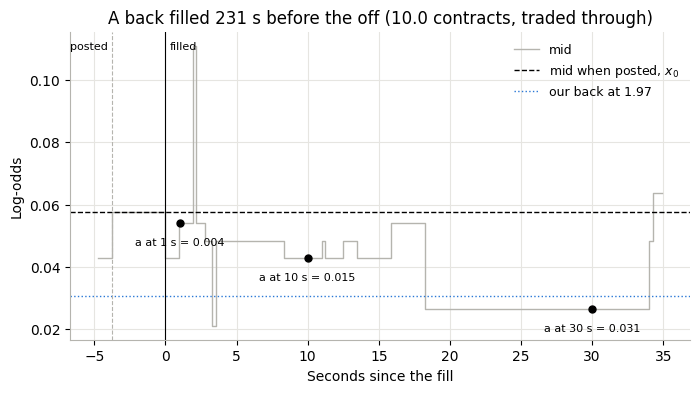

In [6]:
race = FILES[0]
backs = (fills["side"] == "back") & fills["distance"].between(0.025, 0.05)
typical = fills.loc[backs, "a_30"].median()
candidates = fills[backs & (fills["race"] == race.stem) & (fills["fill_ttj"] > 100)
                   & ((fills["fill_time"] - fills["post_time"]).dt.total_seconds() < 5)]
example = candidates.loc[(candidates["a_30"] - typical).abs().idxmin()]   # 30 s markout closest to the median

book = load_book(race)
book = book[book["selection_id"] == example["selection_id"]]
seconds = (book["publish_time"] - example["fill_time"]).dt.total_seconds()    # seconds since the fill
posted_at = (example["post_time"] - example["fill_time"]).total_seconds()
shown = seconds.between(posted_at - 1, 35)
quote_x = -np.log(example["price"] - 1)                                       # the quote's price in log-odds

fig, ax = plt.subplots()
ax.step(seconds[shown], book["x"][shown], where="post", color=GREY, lw=1, label="mid")
ax.axhline(example["x0"], color="black", lw=1, ls="--", label="mid when posted, $x_0$")
ax.axhline(quote_x, color=COLOURS["back"], lw=1, ls=":", label=f"our back at {example['price']}")
ax.axvline(posted_at, color=GREY, lw=0.8, ls="--")
ax.axvline(0, color="black", lw=0.8)
ax.text(posted_at - 0.3, 0.97, "posted", transform=ax.get_xaxis_transform(), ha="right", va="top", fontsize=8)
ax.text(0.3, 0.97, "filled", transform=ax.get_xaxis_transform(), ha="left", va="top", fontsize=8)
for h in [1, 10, 30]:
    ax.plot(h, example["x0"] - example[f"a_{h}"], "o", color="black", ms=5)
    ax.annotate(f"a at {h} s = {example[f'a_{h}']:.3f}", (h, example["x0"] - example[f"a_{h}"]),
                textcoords="offset points", xytext=(0, -16), ha="center", fontsize=8)
ax.set(xlabel="Seconds since the fill", ylabel="Log-odds",
       title=f"A back filled {example['fill_ttj']:.0f} s before the off "
             f"({example['contracts']:.1f} contracts, {example['how']})")
ax.legend(frameon=False, fontsize=9, loc="best")
plt.show()

## Step 3: The markout curve

To compare horizons fairly, every point on the curve has to use the same fills. So we use the fills that happened at least 150 s before the off (enough room for a 120 s markout before $T$) and that have a markout at every horizon. Each fill counts in proportion to its contracts.

**Confidence intervals by bootstrapping.** How much would the curve change if January had given us a different set of races? We can't rerun January, so we imitate it. We draw 3,954 races at random from our 3,954, with replacement, so some races get picked twice and some not at all. Then we recompute the curve from that sample, and repeat 1,000 times. The spread of those 1,000 curves shows how much the result depends on which races we happened to get. The middle 95% of them is the 95% confidence interval. This is the same method as in the σ² and k notebooks.

We resample whole races rather than single fills because fills in the same race are related: one big move produces lots of similar markouts. Treating them as independent would make the intervals look narrower than they really are. A race's total of (markout × contracts) and its total contracts are all we need, so a bootstrap sample just counts each race as many times as it was drawn.

In [7]:
MARKOUTS = [f"a_{h}" for h in HORIZONS]
markouts = fills[MARKOUTS].where(fills[MARKOUTS].abs() <= RUNNER_EVENT)    # drop runner events
print(f"{(fills[MARKOUTS].abs() > RUNNER_EVENT).any(axis=1).sum():,} fills had a runner event at some horizon")

RACES = fills["race"].unique()
draws = rng.multinomial(len(RACES), np.full(len(RACES), 1 / len(RACES)), size=N_BOOT)   # draws[b, r] = times race r was picked


def markout_curve(chosen, columns=MARKOUTS):
    # Contract-weighted mean markout at each horizon for the chosen fills, plus the same in every bootstrap repeat
    weight = fills.loc[chosen, "contracts"]
    race = fills.loc[chosen, "race"]
    sums = markouts.loc[chosen, columns].mul(weight, axis=0).groupby(race).sum().reindex(RACES, fill_value=0)
    totals = weight.groupby(race).sum().reindex(RACES, fill_value=0)
    mean = sums.sum() / totals.sum()
    boot = (draws @ sums.to_numpy()) / (draws @ totals.to_numpy())[:, None]   # repeats x horizons
    return mean, boot


def weighted_mean(chosen, column):
    # Contract-weighted mean markout of the chosen fills at one horizon
    return np.average(markouts.loc[chosen, column], weights=fills.loc[chosen, "contracts"])

def ci(boot):
    # 25th and 975th smallest of 1,000 bootstrap values
    ordered = np.sort(boot, axis=0)
    return ordered[24], ordered[974]


early = (fills["fill_ttj"] >= STOP + max(HORIZONS)) & markouts.notna().all(axis=1)
curves = {"all fills": markout_curve(early)}
for side in SIDES:
    curves[side] = markout_curve(early & (fills["side"] == side))
print(f"{early.sum():,} fills at least 150 s before the off, with a markout at every horizon")

1,330 fills had a runner event at some horizon


444,276 fills at least 150 s before the off, with a markout at every horizon


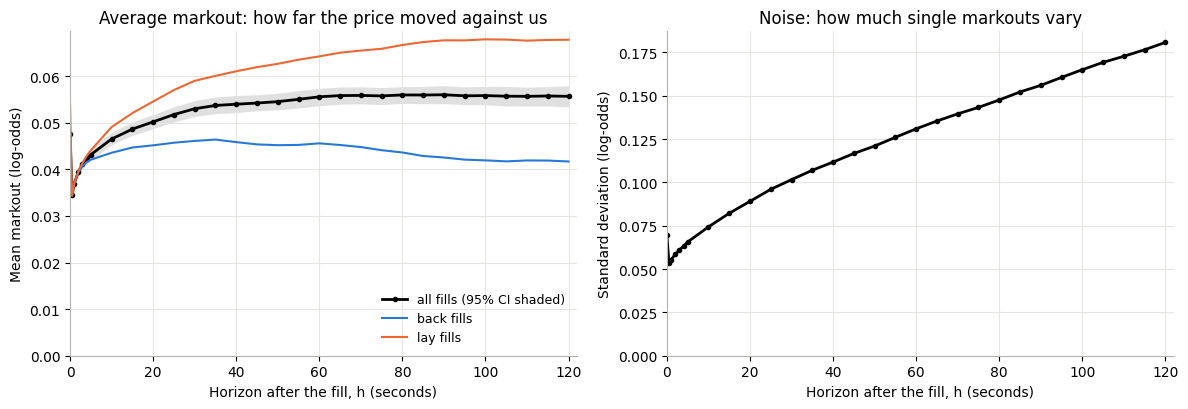

,mean markout,95% CI low,95% CI high,std dev
horizon,,,,
0 s,0.0475,0.0463,0.0487,0.0695
0.5 s,0.0344,0.0336,0.0354,0.0533
1 s,0.0369,0.0360,0.0380,0.0554
2 s,0.0395,0.0385,0.0407,0.0584
3 s,0.0410,0.0399,0.0423,0.0609
4 s,0.0422,0.0411,0.0435,0.0632
5 s,0.0431,0.0419,0.0445,0.0656
10 s,0.0465,0.0453,0.0479,0.0743
15 s,0.0486,0.0473,0.0502,0.0822


In [8]:
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4.2))

mean, boot = curves["all fills"]
low, high = ci(boot)
left.fill_between(HORIZONS, low, high, color="black", alpha=0.12, lw=0)
left.plot(HORIZONS, mean, "-o", color="black", lw=2, ms=3, label="all fills (95% CI shaded)")
for side in SIDES:
    left.plot(HORIZONS, curves[side][0], "-", color=COLOURS[side], lw=1.5, label=f"{side} fills")
left.set(title="Average markout: how far the price moved against us",
         ylabel="Mean markout (log-odds)", ylim=(0, None))
left.legend(frameon=False, fontsize=9, loc="lower right")

# Contract-weighted standard deviation of single markouts
weight = fills.loc[early, "contracts"]
spread = np.sqrt(((markouts.loc[early, MARKOUTS] - mean) ** 2).mul(weight, axis=0).sum() / weight.sum())
right.plot(HORIZONS, spread, "-o", color="black", lw=2, ms=3)
right.set(title="Noise: how much single markouts vary", ylabel="Standard deviation (log-odds)", ylim=(0, None))

for ax in (left, right):
    ax.set(xlabel="Horizon after the fill, h (seconds)", xlim=(0, 122))
fig.tight_layout()
plt.show()

pd.DataFrame({"mean markout": mean.to_numpy(), "95% CI low": low, "95% CI high": high, "std dev": spread.to_numpy()},
             index=[f"{h:g} s" for h in HORIZONS]).rename_axis("horizon").round(4)

Three things stand out.

**A bounce at the fill.** The markout at h = 0 (0.048) is higher than at 0.5 s (0.034). At the moment of a fill, the trade has often just cleared a price, so the mid jumps. Within half a second new orders fill the gap and the mid comes partly back. That looks like temporary pressure from the trade rather than information, so h = 0 isn't a fair measure.

**Then a fast rise that flattens out.** After the bounce the average markout climbs quickly, to 0.047 at 10 s and 0.053 at 30 s, and then much more slowly: it reaches 0.056 by about 60 s and stays there out to 120 s. Most of what a fill tells us reaches the price within about half a minute.

**The noise keeps growing.** The standard deviation of single markouts nearly doubles between 1 s and 30 s (0.055 to 0.102) and nearly doubles again by 120 s (0.181), while the average has stopped rising. Past the first half-minute or so, a longer horizon mostly adds noise.

Backs and lays behave a little differently. Back markouts peak at about 35 s and ease off slightly after that, while lay markouts keep creeping up until about 100 s.

## Step 4: Closer to the off

The curve above only uses fills at least 150 s before the off. Fills nearer the off have less room before $T$, so each time bin below only goes up to the longest horizon all of its fills allow (for example, 10 s for fills 45–60 s before the off). Each line still uses the same fills at every point.

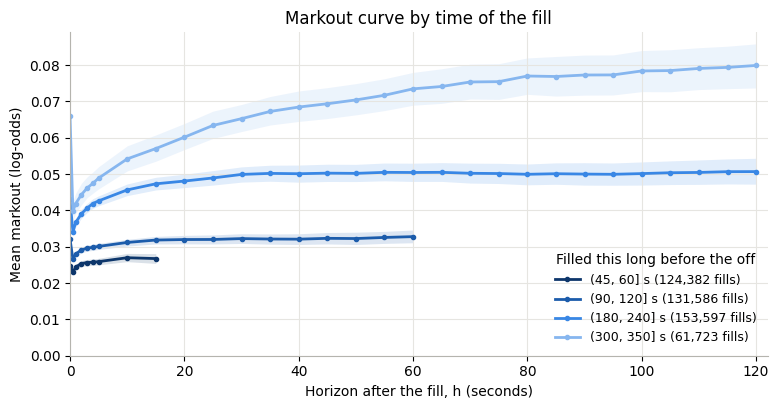

,"(45, 60]","(90, 120]","(180, 240]","(300, 350]"
horizon,,,,
0 s,0.0248,0.0321,0.0430,0.0659
0.5 s,0.0230,0.0266,0.0341,0.0398
1 s,0.0244,0.0280,0.0367,0.0419
2 s,0.0254,0.0291,0.0391,0.0443
3 s,0.0256,0.0296,0.0406,0.0462
4 s,0.0257,0.0298,0.0419,0.0474
5 s,0.0259,0.0301,0.0426,0.0489
10 s,0.0270,0.0312,0.0456,0.0542
15 s,0.0267,0.0318,0.0473,0.0570


In [9]:
BIN_EDGES = [30, 45, 60, 90, 120, 180, 240, 300, 350]   # same time bins as the σ² and k notebooks
SHOWN = [(45, 60), (90, 120), (180, 240), (300, 350)]
RAMP = ["#0d366b", "#1c5cab", "#3987e5", "#86b6ef"]     # dark = close to the off, light = far from it

fig, ax = plt.subplots(figsize=(9, 4.2))
by_bin = {}
for (lo, hi), colour in zip(SHOWN, RAMP):
    columns = [f"a_{h}" for h in HORIZONS if h <= lo - STOP]      # horizons every fill in the bin has room for
    chosen = fills["fill_ttj"].between(lo, hi, inclusive="right") & markouts[columns].notna().all(axis=1)
    mean, boot = markout_curve(chosen, columns)
    low, high = ci(boot)
    by_bin[f"({lo}, {hi}]"] = mean
    horizons = HORIZONS[:len(columns)]
    ax.fill_between(horizons, low, high, color=colour, alpha=0.15, lw=0)
    ax.plot(horizons, mean, "-o", color=colour, lw=2, ms=3, label=f"({lo}, {hi}] s ({chosen.sum():,} fills)")
ax.set(xlabel="Horizon after the fill, h (seconds)", ylabel="Mean markout (log-odds)", ylim=(0, None),
       xlim=(0, 122), title="Markout curve by time of the fill")
ax.legend(title="Filled this long before the off", frameon=False, fontsize=9)
plt.show()

pd.DataFrame(by_bin).reindex(MARKOUTS).rename(index=lambda c: c.replace("a_", "") + " s").rename_axis("horizon").round(4)

The closer to the off a fill happens, the sooner its markout levels off. For fills 45–60 s before the off, the curve is flat after about 5–10 s. For fills 90–120 s out it flattens after about 10–15 s, and for 180–240 s out after about 30 s.

The earliest fills are different. 300–350 s before the off, the markout is still rising at 120 s: when someone trades against us five minutes or more before the off, the price tends to keep drifting the same way for at least another two minutes. Quotes posted that early are under 7% of filled contracts, and for them a short horizon will understate the move (more on this below).

## Step 5: Applying the rule

For each bootstrap repeat, we divide that repeat's curve by its own 120 s level, so we get a confidence interval for the share of the move reached at each horizon. Then we take the shortest horizon from which the share stays at or above 90%, at that horizon and every longer one, even at the low end of the interval.

The "stays" matters because of the bounce at the fill. For the widest quotes, the markout at the moment of the fill can already be above 90% of the 120 s level, before it drops back and climbs again. That spike isn't the move settling, so it shouldn't count.

In [10]:
def share_of_120(chosen):
    # Each horizon's markout as a share of the 120 s level, with a 95% CI
    mean, boot = markout_curve(chosen)
    low, high = ci(boot / boot[:, [-1]])        # each repeat's curve over its own 120 s level
    return (mean / mean.iloc[-1]).to_numpy(), low, high


def rule(chosen):
    # The shortest horizon from which the share stays at or above 90% (at the low end of its CI)
    _, low, _ = share_of_120(chosen)
    for i, h in enumerate(HORIZONS):
        if (low[i:] >= TARGET_SHARE).all():
            return h


share, low, high = share_of_120(early)
H = rule(early)
print(f"Chosen markout horizon: h = {H:g} s\n")
pd.DataFrame({"share of 120 s level": share, "95% CI low": low, "95% CI high": high},
             index=[f"{h:g} s" for h in HORIZONS]).rename_axis("horizon").round(3)

Chosen markout horizon: h = 30 s



,share of 120 s level,95% CI low,95% CI high
horizon,,,
0 s,0.853,0.817,0.895
0.5 s,0.618,0.592,0.648
1 s,0.664,0.636,0.696
2 s,0.709,0.679,0.745
3 s,0.737,0.705,0.775
4 s,0.759,0.725,0.797
5 s,0.775,0.740,0.815
10 s,0.835,0.799,0.877
15 s,0.874,0.835,0.917


Does the same horizon work for every kind of fill? Below is the share of the 120 s level that each group has reached at the chosen $h$, using the same fills as Step 3.

In [11]:
chosen_column = f"a_{H}"
groups = {"all fills": early}
groups.update({f"{side} fills": early & (fills["side"] == side) for side in SIDES})
band = distance_band(fills["distance"])
groups.update({f"distance {label}": early & (band == label) for label in BAND_LABELS})
for lo, hi in [(150, 180), (180, 240), (240, 300), (300, 350)]:
    groups[f"filled ({lo}, {hi}] s before the off"] = early & fills["fill_ttj"].between(lo, hi, inclusive="right")

check = pd.DataFrame({
    "fills": {name: chosen.sum() for name, chosen in groups.items()},
    f"markout at {H:g} s": {name: weighted_mean(chosen, chosen_column) for name, chosen in groups.items()},
    "markout at 120 s": {name: weighted_mean(chosen, "a_120") for name, chosen in groups.items()},
})
check["share reached"] = check[f"markout at {H:g} s"] / check["markout at 120 s"]
check.round(3)

,fills,markout at 30 s,markout at 120 s,share reached
all fills,444276,0.053,0.056,0.952
back fills,198198,0.046,0.042,1.106
lay fills,246078,0.059,0.068,0.870
distance 0-0.025,223336,0.040,0.041,0.979
distance 0.025-0.05,101965,0.052,0.055,0.958
distance 0.05-0.10,80793,0.067,0.071,0.938
distance 0.10-0.20,38182,0.099,0.109,0.909
"filled (150, 180] s before the off",99164,0.041,0.042,0.978
"filled (180, 240] s before the off",153597,0.050,0.051,0.985
"filled (240, 300] s before the off",129776,0.059,0.059,0.996


We chose how many quotes to post at each distance, and any average over all quotes depends on that choice. Wide quotes tend to have bigger markouts, with more of the move still to come. So we also apply the rule to each distance band on its own.

In [12]:
pd.DataFrame({
    "fills": {label: (early & (band == label)).sum() for label in BAND_LABELS},
    "h picked by the rule (s)": {label: rule(early & (band == label)) for label in BAND_LABELS},
}).rename_axis("distance from the mid (log-odds)")

,fills,h picked by the rule (s)
distance from the mid (log-odds),,
0-0.025,223336,20
0.025-0.05,101965,30
0.05-0.10,80793,35
0.10-0.20,38182,45


**So h = 30 s.** At 25 s the curve has reached 93% on average, but the low end of its confidence interval is 89%, so it doesn't pass the rule. From 30 s onwards, the low end stays above 91%.

How well 30 s works for different kinds of fill:

- Back fills have reached all of their 120 s level, because backs peak earlier, and lay fills have reached 87%.
- Every distance band reaches over 90% at 30 s, from 98% for the quotes closest to the mid down to 91% for the widest. Applied to each band on its own, the rule picks 20 s for the closest quotes and 30–45 s for wider ones, probably because wider quotes are only filled by bigger moves, which take longer to play out. One horizon for all quotes keeps the target simple, and 30 s sits in the middle of that range.
- Fills between 150 and 300 s before the off reach 98% or more. The exception is the earliest fills, 300–350 s out, at 82%, because their prices keep drifting (Step 4). A 30 s markout understates the move for those fills, but they're a small share, and they still have the largest markouts at 30 s, so the model will still charge them the most.

**What this means for the model.** The target is the markout at 30 s, or at $T$ if that comes first. Fills in the last 30 s before $T$ get a shorter horizon, which loses little, since near the off the curve is flat after a few seconds. The 30 s markout is noisy (a standard deviation of about 0.10 log-odds against an average of about 0.05), so the model needs plenty of data, and we have about 930,000 filled quotes.

## Step 6: The data for the model

The model will learn to predict the markout at $h$ = 30 s. For a fill less than 30 s before $T$, that would run past $T$, so we measure at $T$ instead, which is when the strategy closes its position anyway. Runner events get no target.

The model works with quotes, because that's where its prediction is used: when we post a quote, we want to know how far the price is likely to move against it if it's filled. So a quote filled in several pieces becomes one row. Its markout is the contract-weighted average over its pieces, and its weight is the number of contracts filled.

The saved file keeps only what the model and its features need:

| Column | What it is | Units | Used for |
|---|---|---|---|
| `market_id` | Betfair's id for the race (its WIN market) | text | Finding the race's order book when building features. Keeping all of a race's quotes together when the data is split or bootstrapped. |
| `runner_id` | Betfair's id for the greyhound | number | Finding the runner's prices in the order book. |
| `side` | Whether our quote was a back or a lay | `back` or `lay` | Feature. |
| `quote_odds` | The odds our quote was posted at | decimal odds | Features: how far the quote is from the mid (in log-odds and in ticks), and where it sits in the order book. |
| `posted_at` | When the quote was posted | date and time (UTC) | Building every feature from the order book as it was at this moment, and never later. |
| `seconds_to_off` | How long before the scheduled off the quote was posted | seconds | Feature. |
| `mid_log_odds` | The runner's mid price when the quote was posted, $x_0$ | log-odds | Feature (the runner's price level). It's also the point the markout is measured from. |
| `contracts_filled` | How many of the quote's 10 contracts were filled | contracts | Weight: a quote filled for 10 contracts counts ten times as much as one filled for 1. |
| `markout` | How far the price moved against us 30 s after each fill (or at $T$), averaged over the quote's fills by contracts | log-odds (positive = against us) | Target: what the model learns to predict. |

Everything else is left out on purpose. The markouts at other horizons were only needed to choose $h$. How and when a quote was filled are only known after the fact, so the model must never see them.

Neighbouring quotes are often filled by the same price move, so their markouts can be almost identical (the first rows below are an example). That's expected. The model will always be tested on races it hasn't seen, so these near-copies can't make it look better than it really is.

In [13]:
full_horizon = fills["fill_ttj"] - H >= STOP
fills["target"] = fills[f"a_{H}"].where(full_horizon, fills["a_T"])             # at T if h would run past it
fills["target"] = fills["target"].where(fills["target"].abs() <= RUNNER_EVENT)   # no target for runner events
print(f"{np.average(full_horizon, weights=fills['contracts']):.0%} of filled contracts are measured at {H:g} s, "
      f"the rest at T")

# One row per quote: contracts filled, and the contract-weighted average markout of its pieces
QUOTE = ["race", "selection_id", "side", "price", "post_time", "post_ttj", "x0"]
pieces = fills[fills["target"].notna()]
quotes = (pieces.assign(weighted=pieces["target"] * pieces["contracts"])
          .groupby(QUOTE, as_index=False)[["contracts", "weighted"]].sum())
quotes["target"] = quotes.pop("weighted") / quotes["contracts"]
print(f"{len(quotes):,} filled quotes with a target")

# Readable names, and only the columns the model and its features need
NAMES = {"race": "market_id", "selection_id": "runner_id", "side": "side", "price": "quote_odds",
         "post_time": "posted_at", "post_ttj": "seconds_to_off", "x0": "mid_log_odds",
         "contracts": "contracts_filled", "target": "markout"}
model_data = quotes[list(NAMES)].rename(columns=NAMES).reset_index(drop=True)

SAVE_TO.parent.mkdir(exist_ok=True)
model_data.to_parquet(SAVE_TO)
print(f"Saved to {SAVE_TO.relative_to(ROOT).as_posix()}")
model_data.head()

77% of filled contracts are measured at 30 s, the rest at T


928,816 filled quotes with a target


Saved to adverse-selection/data/pretend_fills_jan.parquet


,market_id,runner_id,side,quote_odds,posted_at,seconds_to_off,mid_log_odds,contracts_filled,markout
0,1.237721878,77928213,back,4.1,2025-01-01 00:35:38.018000+00:00,261.982,-1.118734,10.0,0.304838
1,1.237721878,77928213,back,4.2,2025-01-01 00:35:38.018000+00:00,261.982,-1.118734,10.0,0.304838
2,1.237721878,77928213,back,4.3,2025-01-01 00:35:38.018000+00:00,261.982,-1.118734,10.0,0.304838
3,1.237721878,77928213,back,4.4,2025-01-01 00:35:38.018000+00:00,261.982,-1.118734,10.0,0.304838
4,1.237721878,77928213,back,4.4,2025-01-01 00:36:05.850000+00:00,234.150,-1.197552,10.0,0.226019
